# ECSE 412 Project
by **Arda Kaan Yildirim** 261164821</br>
and **Ryan Young**

## Least Mean Squared Method

Importing the DSP libraries + matplotlib for jupyter

In [50]:
import scipy.signal as sig
import numpy as np
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats

Need to find a *numpy* way of initializing some of these...

In [31]:
x = [0]
s = [0]
i = [0]
e = [0]

**The feedback loop**
- Create loop
  - produce `e[n] = x[n] - i_processed[n]`
  - calculate `h[k,n+1] = h[k,n] + mu * e[n] * x[n - delay - k]`
  - calculate `i_processed[n+1] = h[k,n] convolved with x[n]`
  - plot mean-square error (formula from class slides)

In [32]:
def lms(x, M, nD, mu):
    h = [np.zeros(M + 1)]     # weights; h[n][k]
    e = np.zeros(N)
    for n in range(nD + M, len(x)):
        x_in = x[n - nD - np.arange(M + 1)]         # [x[n-nD], ..., x[n-nD-M]]
        e[n] = x[n] - h[-1] @ x_in                  # e[n] = x[n] - ihat[n]
        h.append(h[-1] + mu * e[n] * x_in)          # LMS update -> h[:, n+1]
    return e,h

Experiment Setup with Parameters:
- **Number of Weights = 4**
- μ's = 1E-4, 3E-4, 1E-3, 3E-3
- ω = 0.2π
- Number of runs = 100

In [63]:
rng = np.random.default_rng(412)
N, runs = 1000, 100                 # samples per run, independent runs
M, nD = 4, 2                        # 4 taps, delay (white-noise case)
SIR_dB = -10                        # SIR = 10 log10(sigma_s^2 / (A^2/2))
A = np.sqrt(2 * 10**(-SIR_dB / 10)) # interference amplitude (~4.47)
w0 = 0.2 * np.pi                    # interference frequency (rad/sample)
mus = [1e-4, 5e-4, 1e-3, 5e-3]      # all below 2/((M+1)*var(x)) ~ 0.0119

Experiment Setup with Parameters:
- **Number of Weights = 8**
- μ's = 1E-4, 3E-4, 1E-3, 3E-3
- ω = 0.2π
- Number of runs 100

In [54]:
rng = np.random.default_rng(412)
N, runs = 1000, 100                 # samples per run, independent runs
M, nD = 8, 2                        # 8 taps, delay (white-noise case)
SIR_dB = -10                        # SIR = 10 log10(sigma_s^2 / (A^2/2))
A = np.sqrt(2 * 10**(-SIR_dB / 10)) # interference amplitude (~4.47)
w0 = 0.2 * np.pi                    # interference frequency (rad/sample)
mus = [1e-4, 5e-4, 1e-3, 5e-3]      # all below 2/((M+1)*var(x)) ~ 0.0119

Experiment Setup with Parameters:
- **Number of Weights = 16**
- μ's = 1E-4, 3E-4, 1E-3, 3E-3
- ω = 0.2π
- Number of runs 100

In [58]:
rng = np.random.default_rng(412)
N, runs = 1000, 100                 # samples per run, independent runs
M, nD = 16, 2                        # 8 taps, delay (white-noise case)
SIR_dB = -10                        # SIR = 10 log10(sigma_s^2 / (A^2/2))
A = np.sqrt(2 * 10**(-SIR_dB / 10)) # interference amplitude (~4.47)
w0 = 0.2 * np.pi                    # interference frequency (rad/sample)
mus = [1e-4, 5e-4, 1e-3, 5e-3]      # all below 2/((M+1)*var(x)) ~ 0.0119

**Execute System and Plot**

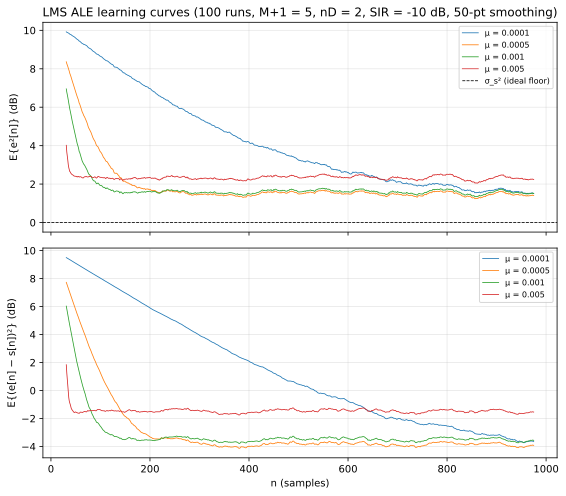

In [64]:
n = np.arange(N)
mse = {mu: np.zeros(N) for mu in mus}  # E{e^2[n]}
res = {mu: np.zeros(N) for mu in mus}  # E{(e[n]-s[n])^2}, residual interference

for r in range(runs):
    s = rng.standard_normal(N)  # sigma_s^2 = 1
    i = A * np.cos(w0 * n + rng.uniform(0, 2 * np.pi))  # random phase each run
    x = s + i
    for mu in mus:  # same realization for every mu
        e, h = lms(x, M, nD, mu)
        mse[mu] += e ** 2 / runs
        res[mu] += (e - s) ** 2 / runs

# ------ Plot the learning curves ------------
smooth = 50
set_matplotlib_formats('svg')
start = nD + M                       # e[n] is undefined before this
ma = lambda p: np.convolve(p, np.ones(smooth) / smooth, mode="valid")
db = lambda p: 10 * np.log10(ma(p[start:]))       # "valid": no edge artifacts
nplot = n[start + smooth // 2 : start + smooth // 2 + N - start - smooth + 1]
fig, ax = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
for mu in mus:
    ax[0].plot(nplot, db(mse[mu]), lw=0.8, label=f"μ = {mu:g}")
    ax[1].plot(nplot, db(res[mu]), lw=0.8, label=f"μ = {mu:g}")
ax[0].axhline(0, color="k", ls="--", lw=0.8, label="σ_s² (ideal floor)")
ax[0].set_ylabel("E{e²[n]} (dB)")
ax[0].set_title(f"LMS ALE learning curves ({runs} runs, M+1 = {M+1}, "
                f"nD = {nD}, SIR = {SIR_dB} dB, {smooth}-pt smoothing)")
ax[1].set_ylabel("E{(e[n] − s[n])²} (dB)")
ax[1].set_xlabel("n (samples)")
for a in ax:
    a.grid(alpha=0.3)
    a.legend(fontsize=8)
fig.tight_layout()
#fig.savefig("lms_learning_curves.png", dpi=150)
plt.show()